In [1]:
import sys
sys.path.append("..")
from src.metrics import mann_whitney_with_effect_size, percentile_quadrant
from src.viz import plot_group_boxplot, plot_quadrant_scatter
from src.db import append_note
import pandas as pd

In [2]:
df_analysis = pd.read_csv("../data/processed/analysis_base.csv")

{'n1': 47, 'n2': 81, 'median1': np.float64(0.0368852459016393), 'median2': np.float64(0.0476190476190476), 'u_stat': np.float64(826.0), 'p_value': np.float64(1.0128892642042861e-07), 'effect_size_r': np.float64(0.5661)}
Đã lưu: ../reports/figures\h1prime_battery_density_boxplot.png


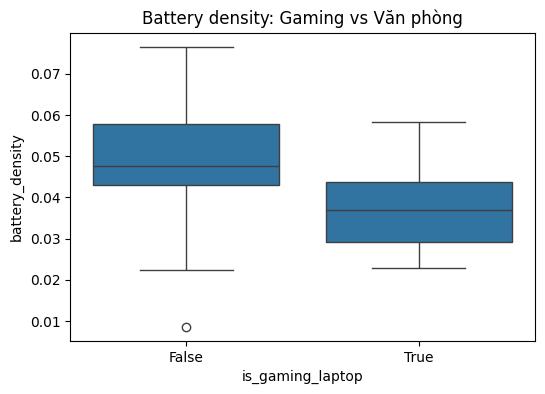

In [ ]:
### [Giai đoạn 3 - B] H1': battery_density gaming vs văn phòng
result_h1prime = mann_whitney_with_effect_size(
    df_analysis.loc[df_analysis["is_gaming_laptop"] == True, "battery_density"],
    df_analysis.loc[df_analysis["is_gaming_laptop"] != True, "battery_density"],
)
print(result_h1prime)
plot_group_boxplot(df_analysis, "is_gaming_laptop", "battery_density",
                    "Battery density: Gaming vs Văn phòng", "h1prime_battery_density_boxplot.png")

note_h1prime = f"""
## [Giai đoạn 3 - Trục 1] H1' — Kết quả

Mann-Whitney battery_density (Gaming vs Văn phòng): {result_h1prime}

**Diễn giải:** median battery_density của gaming ({result_h1prime['median1']:.4f}) thấp hơn
văn phòng ({result_h1prime['median2']:.4f}), effect size r={result_h1prime['effect_size_r']}
(khá lớn) -> xác nhận trade-off: laptop gaming thường nặng hơn so với dung lượng pin.

**Giới hạn:** battery_density đo dung lượng pin DANH ĐỊNH/trọng lượng, không phải hiệu năng
pin thực tế khi sử dụng (xem thêm mục Pivot bên dưới).
"""
append_note(note_h1prime)

In [4]:
### [Giai đoạn 3 - Diagnostic] Kiểm tra độ phủ office_battery_per_whr trên population đã lọc sạch
cols_to_check = ["office_battery_result_minutes", "battery_capacity_whr",
                  "office_battery_per_whr", "battery_density", "interest_score"]
coverage = pd.DataFrame({
    "column": cols_to_check,
    "non_null_count": [df_analysis[c].notna().sum() for c in cols_to_check],
    "null_pct": [df_analysis[c].isna().mean() for c in cols_to_check],
})
display(coverage)
print(f"Tổng số laptop trong analysis_base.csv: {len(df_analysis)}")

,column,non_null_count,null_pct
0,office_battery_result_minutes,1,0.992593
1,battery_capacity_whr,132,0.022222
2,office_battery_per_whr,1,0.992593
3,battery_density,128,0.051852
4,interest_score,135,0.000000


Tổng số laptop trong analysis_base.csv: 135


In [5]:
### [Giai đoạn 3 - Pivot] Quyết định: dùng battery_density thay office_battery_per_whr
cov = coverage.set_index("column")
n_total = len(df_analysis)
n_office = int(cov.loc["office_battery_result_minutes", "non_null_count"])
n_density = int(cov.loc["battery_density", "non_null_count"])

pivot_note = f"""
## [Giai đoạn 3 - Pivot] office_battery_per_whr không khả dụng -> chuyển sang battery_density

**Phát hiện:** trên analysis_base.csv ({n_total} laptop, population đã lọc sạch),
office_battery_result_minutes chỉ có {n_office}/{n_total} dòng có dữ liệu
({cov.loc['office_battery_result_minutes','null_pct']:.1%} NULL), kéo theo office_battery_per_whr
cũng chỉ có {n_office}/{n_total} dòng. battery_density (dựa trên battery_capacity_whr từ
laptop_model, KHÔNG phụ thuộc benchmark) có độ phủ tốt: {n_density}/{n_total}
({n_density/n_total:.1%}).

**Quyết định:** thay office_battery_per_whr bằng battery_density cho cả Golden Ratio (H1')
và H9, áp dụng nguyên tắc tương tự lần pivot H1 -> H1' ở Giai đoạn 2.

**Giới hạn:** battery_density đo dung lượng pin DANH ĐỊNH/trọng lượng — KHÔNG phải hiệu suất
sử dụng điện thực tế. Insight rút ra phản ánh trade-off THIẾT KẾ, không phải HIỆU NĂNG PIN THỰC TẾ.

office_battery_result_minutes chỉ có {n_office} dòng -> KHÔNG đủ để chạy kiểm định thống kê
(kể cả Spearman H8 backlog). H8 coi như không khả thi, loại khỏi phạm vi.
"""
append_note(pivot_note)
print(pivot_note)


## [Giai đoạn 3 - Pivot] office_battery_per_whr không khả dụng -> chuyển sang battery_density

**Phát hiện:** trên analysis_base.csv (135 laptop, population đã lọc sạch),
office_battery_result_minutes chỉ có 1/135 dòng có dữ liệu
(99.3% NULL), kéo theo office_battery_per_whr
cũng chỉ có 1/135 dòng. battery_density (dựa trên battery_capacity_whr từ
laptop_model, KHÔNG phụ thuộc benchmark) có độ phủ tốt: 128/135
(94.8%).

**Quyết định:** thay office_battery_per_whr bằng battery_density cho cả Golden Ratio (H1')
và H9, áp dụng nguyên tắc tương tự lần pivot H1 -> H1' ở Giai đoạn 2.

**Giới hạn:** battery_density đo dung lượng pin DANH ĐỊNH/trọng lượng — KHÔNG phải hiệu suất
sử dụng điện thực tế. Insight rút ra phản ánh trade-off THIẾT KẾ, không phải HIỆU NĂNG PIN THỰC TẾ.

office_battery_result_minutes chỉ có 1 dòng -> KHÔNG đủ để chạy kiểm định thống kê
(kể cả Spearman H8 backlog). H8 coi như không khả thi, loại khỏi phạm vi.



Số laptop thuộc nhóm Golden Ratio': 24


,id,name,laptop_weight_g,battery_density,is_gaming_laptop
0,1,Asus Zenbook S 14 OLED,1200.0,0.060000,False
8,9,Asus Vivobook S 14,1291.0,0.058095,False
24,25,ASUS Vivobook S 14 OLED S5406MA-PP198WS,1300.0,0.057692,False
26,27,ASUS Zenbook 14 OLED UX3405MA-PP151W,1200.0,0.062500,False
36,37,ASUS Vivobook S 14 M5406WA-PP071WS,1300.0,0.057692,False
45,46,ASUS Vivobook S 14 OLED (S5406),1300.0,0.057692,False
49,50,Acer Swift 14 AI SF14-51-75VP,1200.0,0.054167,False
58,59,Asus Zenbook A14,980.0,0.076531,False
59,60,Asus Zenbook 14 OLED UX3405CA,1275.0,0.058824,False
60,61,Asus ROG Flow Z13 (2025),1200.0,0.058333,True


Đã lưu: ../reports/figures\h1prime_golden_ratio_scatter.png


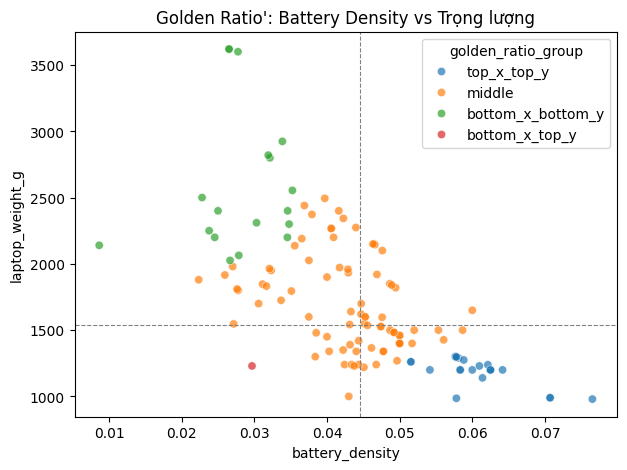

In [ ]:
### [Giai đoạn 3 - B] Golden Ratio' (top 25% battery_density + top 25% nhẹ nhất)
df_analysis["neg_weight"] = -df_analysis["laptop_weight_g"]
df_analysis["golden_ratio_group"] = percentile_quadrant(
    df_analysis, col_x="battery_density", col_y="neg_weight",
    upper_pct=0.75, lower_pct=0.25
)
df_golden = df_analysis[df_analysis["golden_ratio_group"] == "top_x_top_y"]
print(f"Số laptop thuộc nhóm Golden Ratio': {len(df_golden)}")
display(df_golden[["id", "name", "laptop_weight_g", "battery_density", "is_gaming_laptop"]])
df_golden.to_csv("../data/processed/golden_ratio_laptops.csv", index=False)

plot_quadrant_scatter(df_analysis, "battery_density", "laptop_weight_g", "golden_ratio_group",
                       "Golden Ratio': Battery Density vs Trọng lượng", "h1prime_golden_ratio_scatter.png")


note_golden = f"""
## [Giai đoạn 3 - Trục 1] Golden Ratio' — Kết quả

Số laptop thuộc nhóm Golden Ratio' (top 25% battery_density + top 25% nhẹ nhất): {len(df_golden)}
Danh sách: data/processed/golden_ratio_laptops.csv
"""
append_note(note_golden)